# Oxygen Shake Product Analysis

This notebook analyzes Oxygen Shake products across all ROUND_5 daily price and trade data files, plotting their best bid, best ask, and mid price over time.

## 1. Import Libraries and Configure File Paths

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from glob import glob
import warnings
warnings.filterwarnings('ignore')

# Define the ROUND_5 directory
round_5_dir = r'c:\Users\soroc\Downloads\imc-prosperity-4\ROUND_5'

# Get all prices and trades CSV files
prices_files = sorted(glob(os.path.join(round_5_dir, 'prices_round_5_day_*.csv')))
trades_files = sorted(glob(os.path.join(round_5_dir, 'trades_round_5_day_*.csv')))

print(f"Found {len(prices_files)} prices files: {[os.path.basename(f) for f in prices_files]}")
print(f"Found {len(trades_files)} trades files: {[os.path.basename(f) for f in trades_files]}")

Found 3 prices files: ['prices_round_5_day_2.csv', 'prices_round_5_day_3.csv', 'prices_round_5_day_4.csv']
Found 3 trades files: ['trades_round_5_day_2.csv', 'trades_round_5_day_3.csv', 'trades_round_5_day_4.csv']


## 2. Load and Concatenate Daily Prices and Trades CSVs

In [3]:
# Load all prices CSV files and add a day identifier
prices_dfs = []
for file in prices_files:
    day = int(os.path.basename(file).split('_day_')[-1].split('.')[0])
    df = pd.read_csv(file, sep=';')
    df['day'] = day
    prices_dfs.append(df)

# Concatenate all prices dataframes
prices_df = pd.concat(prices_dfs, ignore_index=True)

# Load all trades CSV files and add a day identifier
trades_dfs = []
for file in trades_files:
    day = int(os.path.basename(file).split('_day_')[-1].split('.')[0])
    df = pd.read_csv(file, sep=';')
    df['day'] = day
    trades_dfs.append(df)

# Concatenate all trades dataframes
trades_df = pd.concat(trades_dfs, ignore_index=True)

print(f"Loaded prices data shape: {prices_df.shape}")
print(f"Loaded trades data shape: {trades_df.shape}")
print(f"\nPrices data columns: {prices_df.columns.tolist()}")
print(f"Trades data columns: {trades_df.columns.tolist()}")

Loaded prices data shape: (1500000, 17)
Loaded trades data shape: (35385, 8)

Prices data columns: ['day', 'timestamp', 'product', 'bid_price_1', 'bid_volume_1', 'bid_price_2', 'bid_volume_2', 'bid_price_3', 'bid_volume_3', 'ask_price_1', 'ask_volume_1', 'ask_price_2', 'ask_volume_2', 'ask_price_3', 'ask_volume_3', 'mid_price', 'profit_and_loss']
Trades data columns: ['timestamp', 'buyer', 'seller', 'symbol', 'currency', 'price', 'quantity', 'day']


## 3. Filter for Oxygen Shake Products

In [4]:
# Filter prices for Oxygen Shake products
oxygen_shake_prices = prices_df[prices_df['product'].str.contains('OXYGEN_SHAKE', case=False, na=False)].copy()

# Filter trades for Oxygen Shake products
oxygen_shake_trades = trades_df[trades_df['symbol'].str.contains('OXYGEN_SHAKE', case=False, na=False)].copy()

print(f"Oxygen Shake prices data shape: {oxygen_shake_prices.shape}")
print(f"Oxygen Shake trades data shape: {oxygen_shake_trades.shape}")

# Get unique Oxygen Shake products
oxygen_shake_products = oxygen_shake_prices['product'].unique()
print(f"\nOxygen Shake products found ({len(oxygen_shake_products)}):")
for product in sorted(oxygen_shake_products):
    print(f"  - {product}")

Oxygen Shake prices data shape: (150000, 17)
Oxygen Shake trades data shape: (3665, 8)

Oxygen Shake products found (5):
  - OXYGEN_SHAKE_CHOCOLATE
  - OXYGEN_SHAKE_EVENING_BREATH
  - OXYGEN_SHAKE_GARLIC
  - OXYGEN_SHAKE_MINT
  - OXYGEN_SHAKE_MORNING_BREATH


## 4. Clean and Prepare Best Bid, Best Ask, and Mid Price Fields

In [5]:
# Extract best bid and best ask prices
oxygen_shake_prices['best_bid'] = oxygen_shake_prices['bid_price_1'].astype(float)
oxygen_shake_prices['best_ask'] = oxygen_shake_prices['ask_price_1'].astype(float)

# Compute mid price as average of best bid and best ask
oxygen_shake_prices['computed_mid_price'] = (oxygen_shake_prices['best_bid'] + oxygen_shake_prices['best_ask']) / 2

# Ensure mid_price column is numeric
oxygen_shake_prices['mid_price'] = pd.to_numeric(oxygen_shake_prices['mid_price'], errors='coerce')

# Create a combined time column (day + timestamp for ordering)
oxygen_shake_prices['time'] = oxygen_shake_prices['day'] * 1000 + oxygen_shake_prices['timestamp']

# Check for missing values
print("Missing values in key columns:")
print(oxygen_shake_prices[['best_bid', 'best_ask', 'mid_price', 'computed_mid_price']].isnull().sum())

# Display sample data
print("\nSample data:")
print(oxygen_shake_prices[['product', 'day', 'timestamp', 'best_bid', 'best_ask', 'mid_price', 'computed_mid_price']].head(10))

Missing values in key columns:
best_bid              0
best_ask              0
mid_price             0
computed_mid_price    0
dtype: int64

Sample data:
                        product  day  timestamp  best_bid  best_ask  \
18       OXYGEN_SHAKE_CHOCOLATE    2          0    9994.0   10006.0   
31  OXYGEN_SHAKE_EVENING_BREATH    2          0    9994.0   10006.0   
34          OXYGEN_SHAKE_GARLIC    2          0    9994.0   10006.0   
42            OXYGEN_SHAKE_MINT    2          0    9994.0   10006.0   
46  OXYGEN_SHAKE_MORNING_BREATH    2          0    9994.0   10006.0   
56       OXYGEN_SHAKE_CHOCOLATE    2        100    9994.0   10006.0   
78  OXYGEN_SHAKE_EVENING_BREATH    2        100    9994.0   10006.0   
80          OXYGEN_SHAKE_GARLIC    2        100    9999.0   10012.0   
88            OXYGEN_SHAKE_MINT    2        100   10002.0   10015.0   
93  OXYGEN_SHAKE_MORNING_BREATH    2        100    9985.0    9998.0   

    mid_price  computed_mid_price  
18    10000.0             10

## 5. Plot Best Bid, Best Ask, and Mid Price Over Time

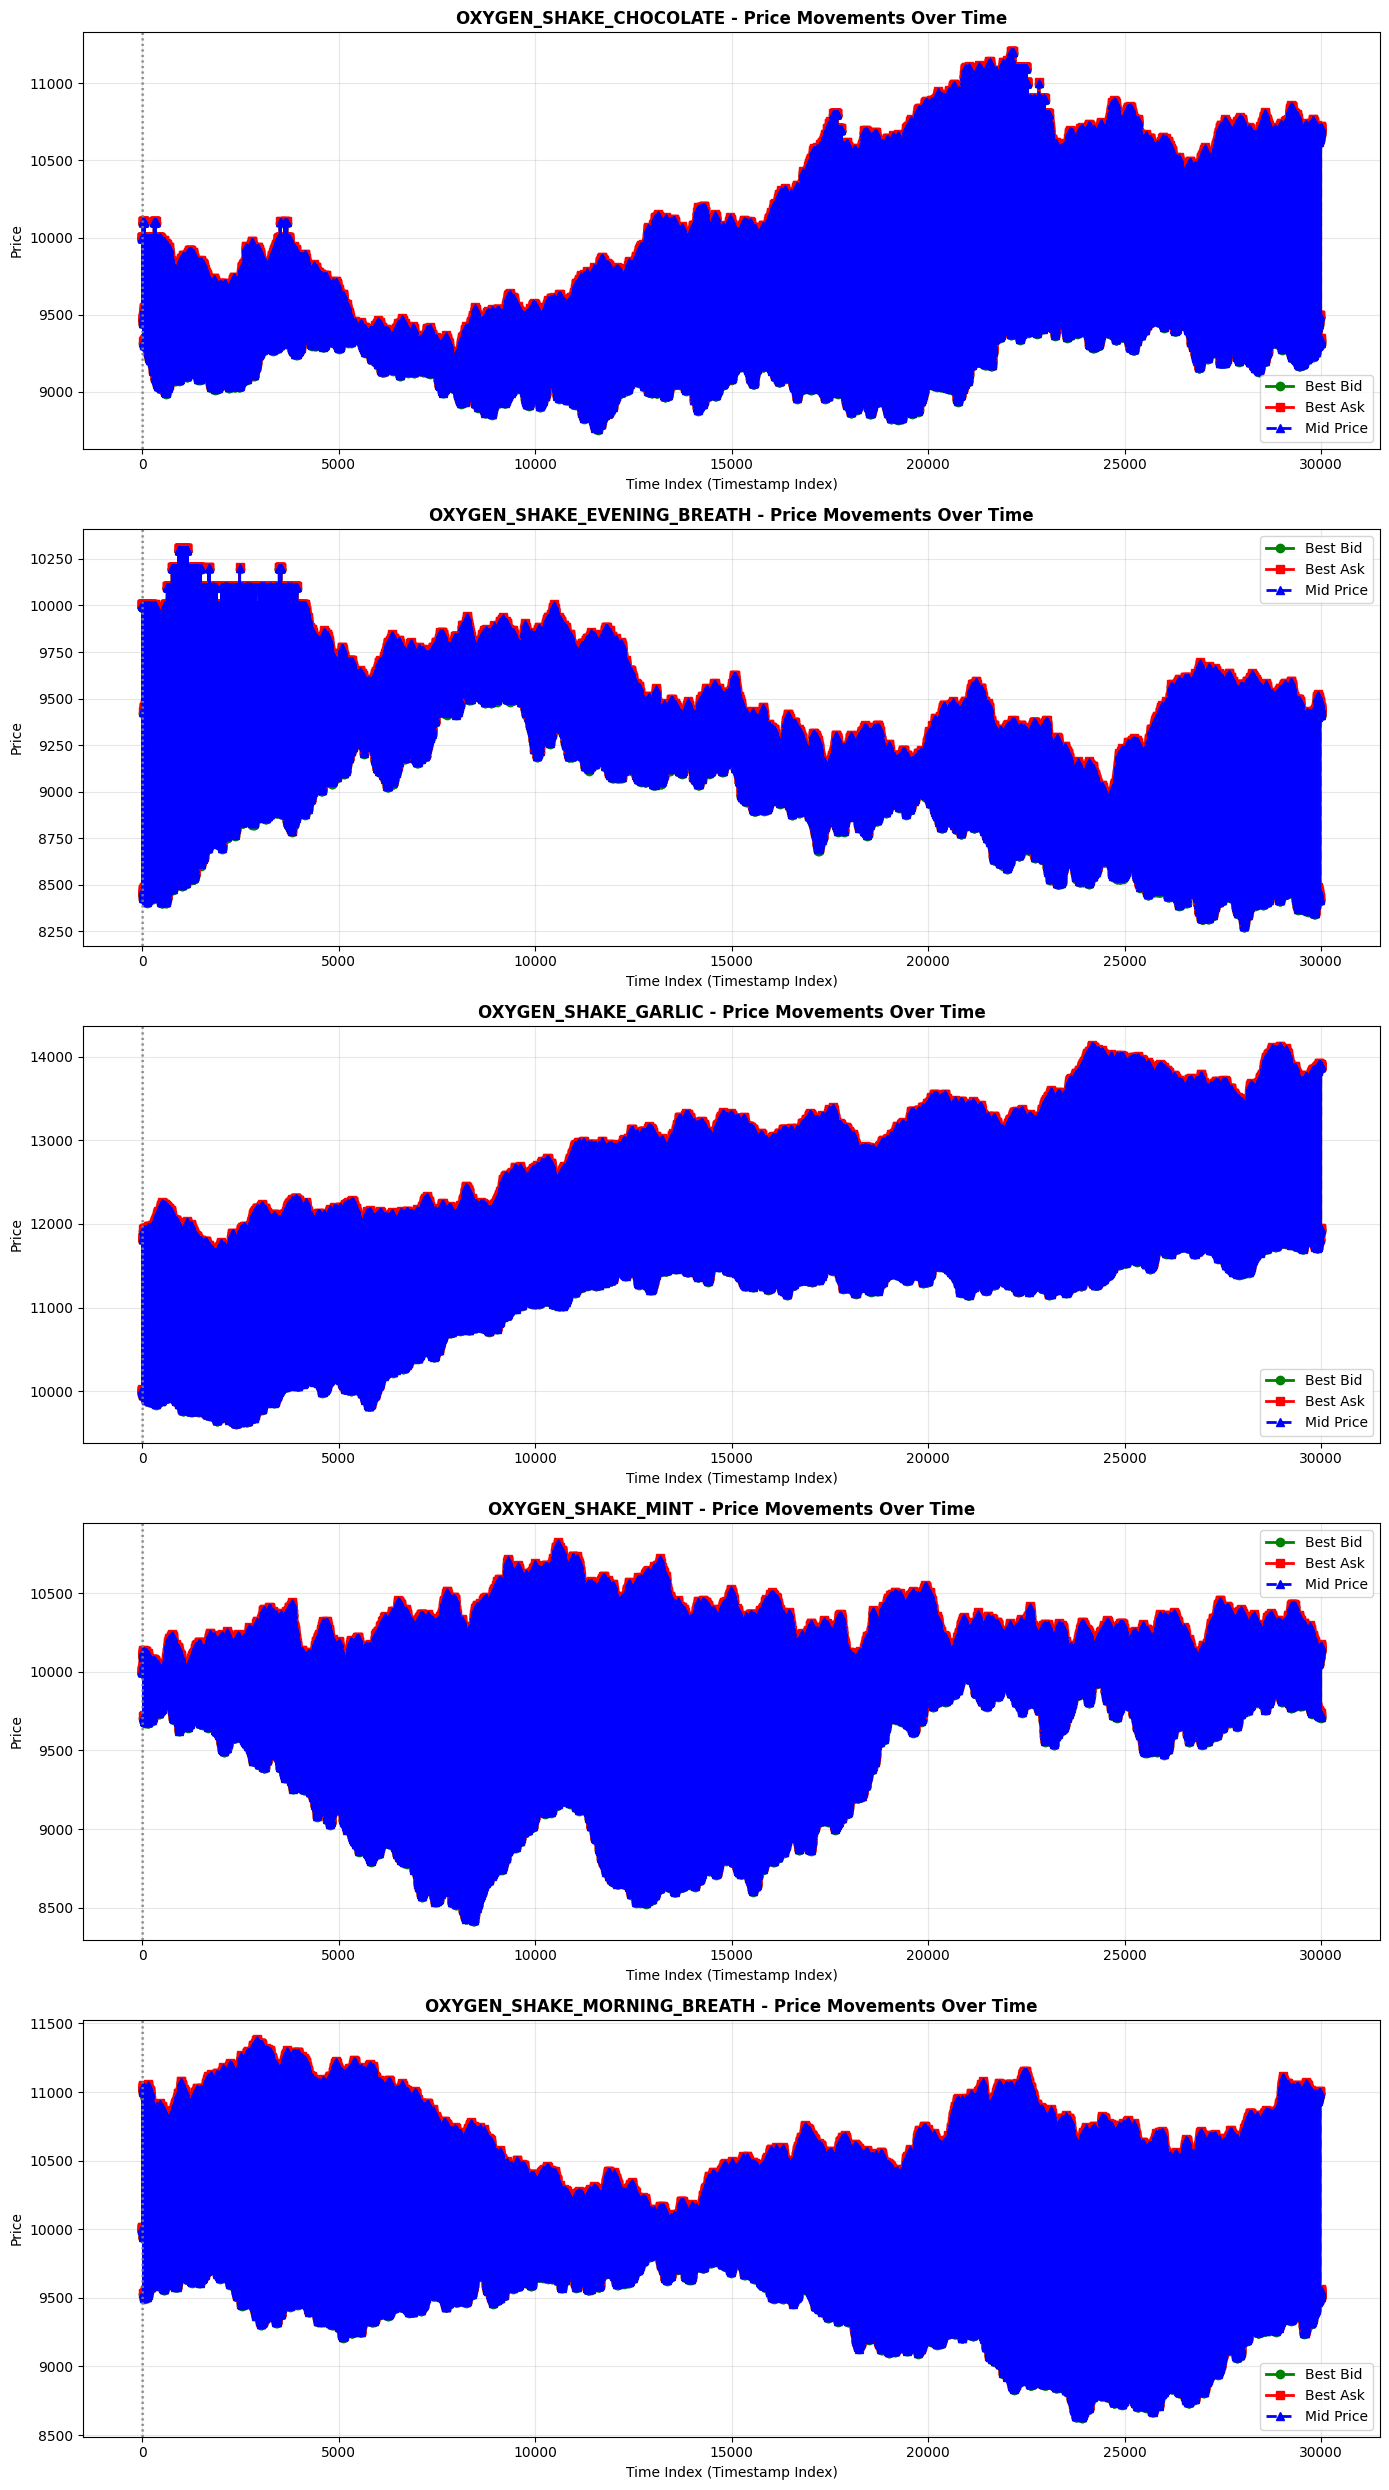

Plot saved as 'oxygen_shake_prices_plot.png'


In [6]:
# Create subplots for each Oxygen Shake product
num_products = len(oxygen_shake_products)
fig, axes = plt.subplots(num_products, 1, figsize=(14, 5 * num_products))

# Handle single product case (axes will be a single Axes object, not an array)
if num_products == 1:
    axes = [axes]

for idx, product in enumerate(sorted(oxygen_shake_products)):
    product_data = oxygen_shake_prices[oxygen_shake_prices['product'] == product].sort_values('time')
    
    ax = axes[idx]
    
    # Plot best bid, best ask, and mid price
    ax.plot(range(len(product_data)), product_data['best_bid'].values, 
            marker='o', linestyle='-', linewidth=2, markersize=6, label='Best Bid', color='green')
    ax.plot(range(len(product_data)), product_data['best_ask'].values, 
            marker='s', linestyle='-', linewidth=2, markersize=6, label='Best Ask', color='red')
    ax.plot(range(len(product_data)), product_data['mid_price'].values, 
            marker='^', linestyle='--', linewidth=2, markersize=6, label='Mid Price', color='blue')
    
    # Customize plot
    ax.set_title(f'{product} - Price Movements Over Time', fontsize=12, fontweight='bold')
    ax.set_xlabel('Time Index (Timestamp Index)', fontsize=10)
    ax.set_ylabel('Price', fontsize=10)
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3)
    
    # Add day boundaries as vertical lines
    for day in product_data['day'].unique():
        day_start_idx = product_data[product_data['day'] == day].index.min()
        if day_start_idx is not None:
            ax.axvline(x=product_data.index.get_loc(day_start_idx), color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(round_5_dir, 'oxygen_shake_prices_plot.png'), dpi=100, bbox_inches='tight')
plt.show()

print("Plot saved as 'oxygen_shake_prices_plot.png'")

## 6. Inspect Summary Statistics and Missing Values

In [7]:
# Summary statistics by product
print("=" * 80)
print("SUMMARY STATISTICS FOR OXYGEN SHAKE PRODUCTS")
print("=" * 80)

for product in sorted(oxygen_shake_products):
    product_data = oxygen_shake_prices[oxygen_shake_prices['product'] == product]
    
    print(f"\n{product}:")
    print(f"  Number of records: {len(product_data)}")
    print(f"  Days covered: {sorted(product_data['day'].unique())}")
    print(f"\n  Best Bid Statistics:")
    print(f"    Min: {product_data['best_bid'].min():.2f}")
    print(f"    Max: {product_data['best_bid'].max():.2f}")
    print(f"    Mean: {product_data['best_bid'].mean():.2f}")
    print(f"    Std Dev: {product_data['best_bid'].std():.2f}")
    
    print(f"\n  Best Ask Statistics:")
    print(f"    Min: {product_data['best_ask'].min():.2f}")
    print(f"    Max: {product_data['best_ask'].max():.2f}")
    print(f"    Mean: {product_data['best_ask'].mean():.2f}")
    print(f"    Std Dev: {product_data['best_ask'].std():.2f}")
    
    print(f"\n  Mid Price Statistics:")
    print(f"    Min: {product_data['mid_price'].min():.2f}")
    print(f"    Max: {product_data['mid_price'].max():.2f}")
    print(f"    Mean: {product_data['mid_price'].mean():.2f}")
    print(f"    Std Dev: {product_data['mid_price'].std():.2f}")
    
    # Check for missing values
    missing = product_data[['best_bid', 'best_ask', 'mid_price']].isnull().sum()
    print(f"\n  Missing values: {missing.sum()} (bid: {missing['best_bid']}, ask: {missing['best_ask']}, mid: {missing['mid_price']})")
    print("-" * 80)

# Overall summary
print(f"\nOverall Oxygen Shake Data:")
print(f"  Total records: {len(oxygen_shake_prices)}")
print(f"  Total unique products: {oxygen_shake_prices['product'].nunique()}")
print(f"  Days covered: {sorted(oxygen_shake_prices['day'].unique())}")
print(f"  Total trades for Oxygen Shake: {len(oxygen_shake_trades)}")

SUMMARY STATISTICS FOR OXYGEN SHAKE PRODUCTS

OXYGEN_SHAKE_CHOCOLATE:
  Number of records: 30000
  Days covered: [np.int64(2), np.int64(3), np.int64(4)]

  Best Bid Statistics:
    Min: 8754.00
    Max: 11193.00
    Mean: 9550.79
    Std Dev: 560.28

  Best Ask Statistics:
    Min: 8766.00
    Max: 11207.00
    Mean: 9562.97
    Std Dev: 560.92

  Mid Price Statistics:
    Min: 8760.00
    Max: 11200.00
    Mean: 9556.88
    Std Dev: 560.60

  Missing values: 0 (bid: 0, ask: 0, mid: 0)
--------------------------------------------------------------------------------

OXYGEN_SHAKE_EVENING_BREATH:
  Number of records: 30000
  Days covered: [np.int64(2), np.int64(3), np.int64(4)]

  Best Bid Statistics:
    Min: 8275.00
    Max: 10293.00
    Mean: 9265.96
    Std Dev: 399.75

  Best Ask Statistics:
    Min: 8280.00
    Max: 10307.00
    Mean: 9277.83
    Std Dev: 399.90

  Mid Price Statistics:
    Min: 8277.50
    Max: 10300.00
    Mean: 9271.90
    Std Dev: 399.82

  Missing values: 0 (b

## 7. Correlation Analysis Between Oxygen Shake Products

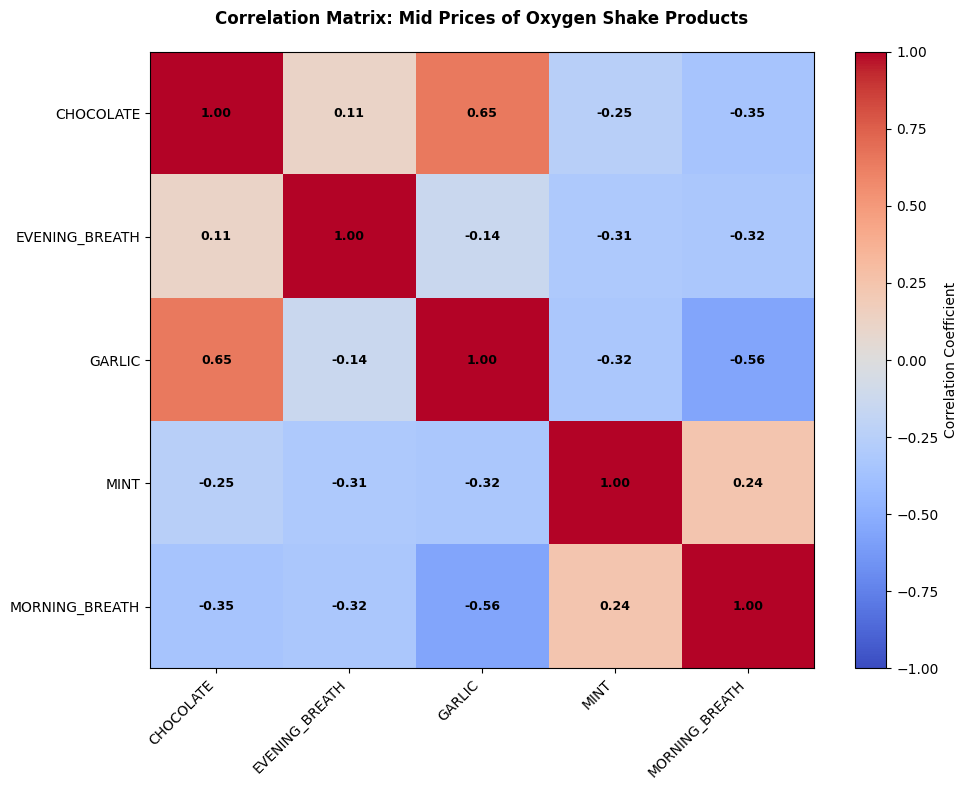

Correlation Matrix:
product                      OXYGEN_SHAKE_CHOCOLATE  \
product                                               
OXYGEN_SHAKE_CHOCOLATE                        1.000   
OXYGEN_SHAKE_EVENING_BREATH                   0.114   
OXYGEN_SHAKE_GARLIC                           0.646   
OXYGEN_SHAKE_MINT                            -0.247   
OXYGEN_SHAKE_MORNING_BREATH                  -0.347   

product                      OXYGEN_SHAKE_EVENING_BREATH  OXYGEN_SHAKE_GARLIC  \
product                                                                         
OXYGEN_SHAKE_CHOCOLATE                             0.114                0.646   
OXYGEN_SHAKE_EVENING_BREATH                        1.000               -0.136   
OXYGEN_SHAKE_GARLIC                               -0.136                1.000   
OXYGEN_SHAKE_MINT                                 -0.305               -0.321   
OXYGEN_SHAKE_MORNING_BREATH                       -0.322               -0.558   

product                   

In [14]:
# Create a pivot table with mid prices for each product at each timestamp
correlation_df = oxygen_shake_prices.pivot_table(
    index=['day', 'timestamp'], 
    columns='product', 
    values='mid_price'
).reset_index()

# Calculate correlation matrix between products
price_columns = [col for col in correlation_df.columns if col not in ['day', 'timestamp']]
correlation_matrix = correlation_df[price_columns].corr()

# Visualize correlation matrix
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(correlation_matrix.values, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')

# Set ticks and labels
ax.set_xticks(range(len(price_columns)))
ax.set_yticks(range(len(price_columns)))
ax.set_xticklabels([col.replace('OXYGEN_SHAKE_', '') for col in price_columns], rotation=45, ha='right')
ax.set_yticklabels([col.replace('OXYGEN_SHAKE_', '') for col in price_columns])

# Add correlation values to cells
for i in range(len(price_columns)):
    for j in range(len(price_columns)):
        text = ax.text(j, i, f'{correlation_matrix.iloc[i, j]:.2f}',
                      ha="center", va="center", color="black", fontsize=9, fontweight='bold')

ax.set_title('Correlation Matrix: Mid Prices of Oxygen Shake Products', fontsize=12, fontweight='bold', pad=20)
plt.colorbar(im, ax=ax, label='Correlation Coefficient')
plt.tight_layout()
plt.savefig(os.path.join(round_5_dir, 'oxygen_shake_correlation_matrix.png'), dpi=100, bbox_inches='tight')
plt.show()

print("Correlation Matrix:")
print(correlation_matrix.round(3))
print("\nCorrelation matrix plot saved as 'oxygen_shake_correlation_matrix.png'")

## 8. Lead-Follower Analysis: Cross-Correlation with Lags

In [15]:
# Calculate lagged cross-correlations to detect lead-follower relationships
from scipy import signal

max_lag = 5  # Check up to 5 timestamp lags

# Store results
lag_results = []

for i, prod1 in enumerate(sorted(oxygen_shake_products)):
    for prod2 in sorted(oxygen_shake_products):
        if prod1 >= prod2:  # Avoid duplicate comparisons
            continue
        
        # Get time series for both products
        series1 = correlation_df[prod1].dropna().values
        series2 = correlation_df[prod2].dropna().values
        
        # Normalize the series
        if len(series1) > 0 and len(series2) > 0:
            series1_norm = (series1 - np.mean(series1)) / np.std(series1)
            series2_norm = (series2 - np.mean(series2)) / np.std(series2)
            
            # Calculate cross-correlation at different lags
            min_len = min(len(series1_norm), len(series2_norm))
            if min_len > max_lag:
                # Pad to same length
                if len(series1_norm) < len(series2_norm):
                    series1_norm = np.pad(series1_norm, (0, len(series2_norm) - len(series1_norm)), 'edge')
                else:
                    series2_norm = np.pad(series2_norm, (0, len(series1_norm) - len(series2_norm)), 'edge')
                
                xcorr = signal.correlate(series2_norm, series1_norm, mode='same')
                xcorr_norm = xcorr / np.max(np.abs(xcorr))
                
                # Find peak correlation and lag
                peak_idx = np.argmax(np.abs(xcorr_norm))
                peak_corr = xcorr_norm[peak_idx]
                lag = peak_idx - len(xcorr_norm) // 2
                
                # Interpretation: positive lag = prod1 leads prod2, negative lag = prod2 leads prod1
                lag_results.append({
                    'Product_1': prod1.replace('OXYGEN_SHAKE_', ''),
                    'Product_2': prod2.replace('OXYGEN_SHAKE_', ''),
                    'Max_Correlation': peak_corr,
                    'Lag': lag,
                    'Interpretation': 'Prod1 leads' if lag > 0 else ('Prod2 leads' if lag < 0 else 'Simultaneous')
                })

lag_results_df = pd.DataFrame(lag_results).sort_values('Max_Correlation', ascending=False, key=abs)

print("\n" + "="*100)
print("LEAD-FOLLOWER ANALYSIS: Cross-Correlation with Lags")
print("="*100)
print("\nInterpretation:")
print("  - Positive Lag: Product 1 LEADS Product 2 (Product 2 follows Product 1)")
print("  - Negative Lag: Product 2 LEADS Product 1 (Product 1 follows Product 2)")
print("  - Max_Correlation: Strength of the relationship at that lag\n")

for _, row in lag_results_df.iterrows():
    print(f"{row['Product_1']} <-> {row['Product_2']}")
    print(f"  Max Correlation: {row['Max_Correlation']:.3f} at Lag: {row['Lag']:+3d}")
    print(f"  Interpretation: {row['Interpretation']}")
    print()


LEAD-FOLLOWER ANALYSIS: Cross-Correlation with Lags

Interpretation:
  - Positive Lag: Product 1 LEADS Product 2 (Product 2 follows Product 1)
  - Negative Lag: Product 2 LEADS Product 1 (Product 1 follows Product 2)
  - Max_Correlation: Strength of the relationship at that lag

CHOCOLATE <-> EVENING_BREATH
  Max Correlation: 1.000 at Lag: -5732
  Interpretation: Prod2 leads

CHOCOLATE <-> GARLIC
  Max Correlation: 1.000 at Lag: -1441
  Interpretation: Prod2 leads

CHOCOLATE <-> MINT
  Max Correlation: -1.000 at Lag: -3862
  Interpretation: Prod2 leads

CHOCOLATE <-> MORNING_BREATH
  Max Correlation: -1.000 at Lag: -8724
  Interpretation: Prod2 leads

EVENING_BREATH <-> GARLIC
  Max Correlation: 1.000 at Lag: -7276
  Interpretation: Prod2 leads

EVENING_BREATH <-> MINT
  Max Correlation: 1.000 at Lag: +14916
  Interpretation: Prod1 leads

EVENING_BREATH <-> MORNING_BREATH
  Max Correlation: 1.000 at Lag: +9673
  Interpretation: Prod1 leads

GARLIC <-> MINT
  Max Correlation: -1.000 at

## 9. Visualize Lead-Follower Relationships

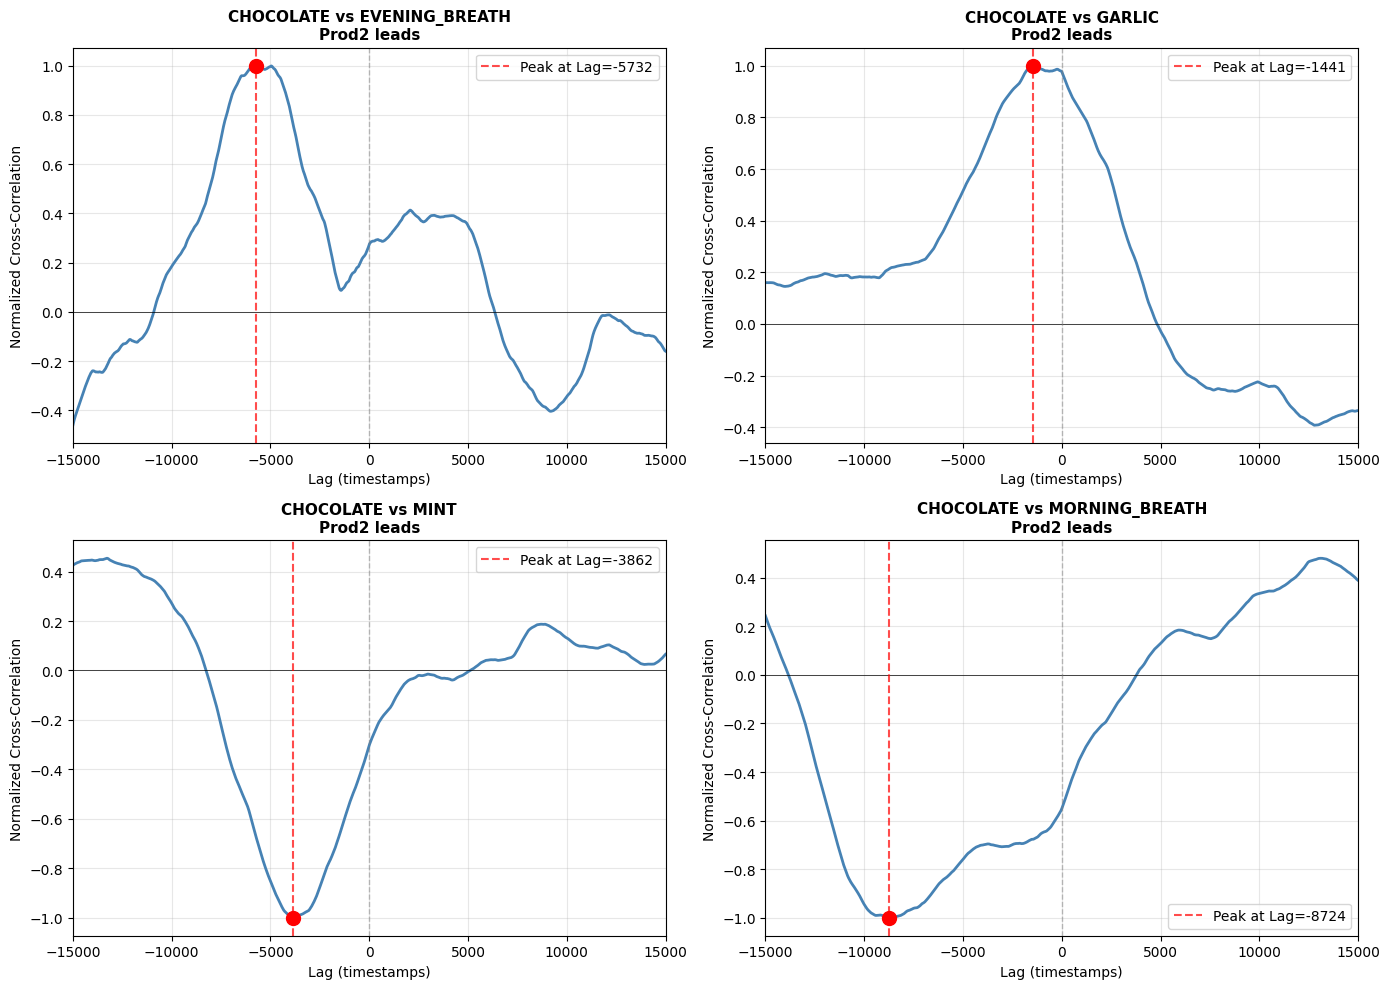

Cross-correlation plots saved as 'oxygen_shake_cross_correlations.png'


In [10]:
# Plot cross-correlations for the top strongest relationships
top_n = min(4, len(lag_results_df))
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (_, row) in enumerate(lag_results_df.head(top_n).iterrows()):
    prod1 = 'OXYGEN_SHAKE_' + row['Product_1']
    prod2 = 'OXYGEN_SHAKE_' + row['Product_2']
    
    # Get time series
    series1 = correlation_df[prod1].dropna().values
    series2 = correlation_df[prod2].dropna().values
    
    # Normalize
    series1_norm = (series1 - np.mean(series1)) / np.std(series1)
    series2_norm = (series2 - np.mean(series2)) / np.std(series2)
    
    # Pad to same length
    if len(series1_norm) < len(series2_norm):
        series1_norm = np.pad(series1_norm, (0, len(series2_norm) - len(series1_norm)), 'edge')
    else:
        series2_norm = np.pad(series2_norm, (0, len(series1_norm) - len(series2_norm)), 'edge')
    
    # Calculate cross-correlation
    xcorr = signal.correlate(series2_norm, series1_norm, mode='same')
    xcorr_norm = xcorr / np.max(np.abs(xcorr))
    lags = np.arange(-len(xcorr_norm)//2, len(xcorr_norm)//2)
    
    ax = axes[idx]
    ax.plot(lags, xcorr_norm, linewidth=2, color='steelblue')
    ax.axhline(y=0, color='k', linestyle='-', linewidth=0.5)
    ax.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
    ax.axvline(x=row['Lag'], color='red', linestyle='--', linewidth=1.5, alpha=0.7, label=f"Peak at Lag={row['Lag']}")
    ax.scatter([row['Lag']], [row['Max_Correlation']], color='red', s=100, zorder=5)
    
    ax.set_xlabel('Lag (timestamps)', fontsize=10)
    ax.set_ylabel('Normalized Cross-Correlation', fontsize=10)
    ax.set_title(f"{row['Product_1']} vs {row['Product_2']}\n{row['Interpretation']}", fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')
    ax.set_xlim(-len(xcorr_norm)//2, len(xcorr_norm)//2)

plt.tight_layout()
plt.savefig(os.path.join(round_5_dir, 'oxygen_shake_cross_correlations.png'), dpi=100, bbox_inches='tight')
plt.show()

print("Cross-correlation plots saved as 'oxygen_shake_cross_correlations.png'")

## 10. Price Momentum and Volatility Analysis


PRICE MOMENTUM AND VOLATILITY ANALYSIS

Products ranked by volatility (most volatile first):

       Product   Mean_Price  Price_Volatility_%  Mean_Price_Change_%  Min_Price  Max_Price  Price_Range  Num_Records
        GARLIC 11925.639767           11.446417             0.650078     9616.0    14126.0       4510.0        30000
MORNING_BREATH 10000.453350            9.696336             0.465575     8631.5    11377.5       2746.0        30000
     CHOCOLATE  9556.879133            8.241130             0.337063     8760.0    11200.0       2440.0        30000
          MINT  9838.394083            7.932903             0.312324     8422.5    10817.0       2394.5        30000
EVENING_BREATH  9271.895000            5.849121             0.169919     8277.5    10300.0       2022.5        30000


Correlation between volatility and momentum: 0.994


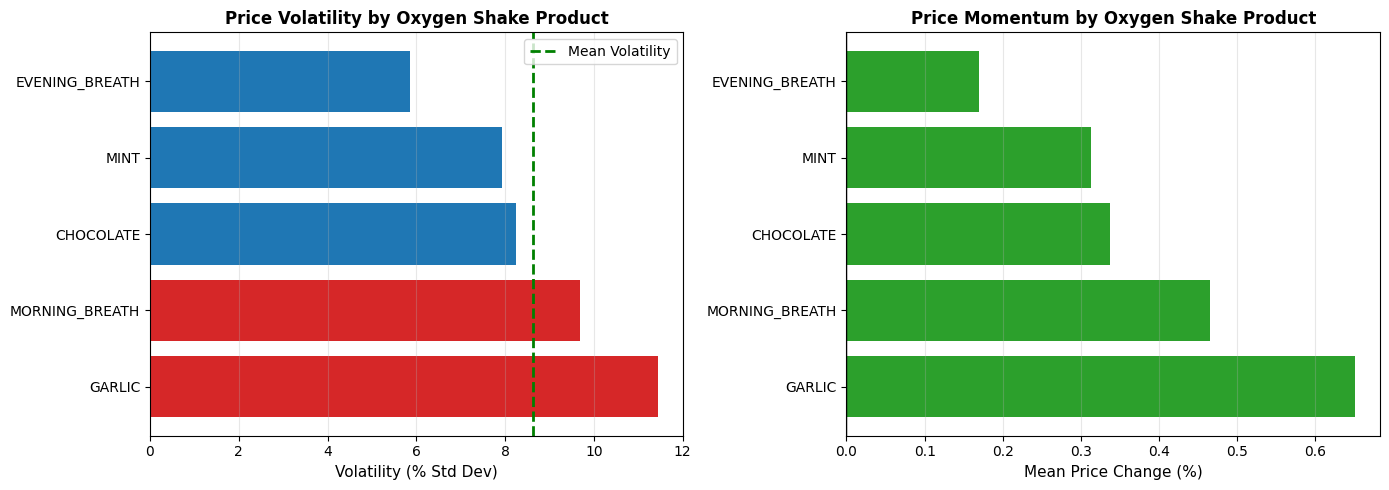



Momentum and volatility plots saved as 'oxygen_shake_momentum_volatility.png'


In [13]:
# Calculate price changes and volatility
momentum_analysis = []

for product in sorted(oxygen_shake_products):
    product_data = oxygen_shake_prices[oxygen_shake_prices['product'] == product].sort_values('time').copy()
    
    # Calculate price changes
    product_data['price_change'] = product_data['mid_price'].diff()
    product_data['price_change_pct'] = product_data['mid_price'].pct_change() * 100
    
    # Calculate rolling volatility (std of price changes)
    if len(product_data) > 1:
        volatility = product_data['price_change_pct'].std()
        momentum = product_data['price_change_pct'].mean()
        
        momentum_analysis.append({
            'Product': product.replace('OXYGEN_SHAKE_', ''),
            'Mean_Price': product_data['mid_price'].mean(),
            'Price_Volatility_%': volatility,
            'Mean_Price_Change_%': momentum,
            'Min_Price': product_data['mid_price'].min(),
            'Max_Price': product_data['mid_price'].max(),
            'Price_Range': product_data['mid_price'].max() - product_data['mid_price'].min(),
            'Num_Records': len(product_data)
        })

momentum_df = pd.DataFrame(momentum_analysis).sort_values('Price_Volatility_%', ascending=False)

print("\n" + "="*100)
print("PRICE MOMENTUM AND VOLATILITY ANALYSIS")
print("="*100)
print("\nProducts ranked by volatility (most volatile first):\n")
print(momentum_df.to_string(index=False))

# Calculate correlation between volatility and momentum
volatility_momentum_corr = momentum_df['Price_Volatility_%'].corr(momentum_df['Mean_Price_Change_%'])
print(f"\n\nCorrelation between volatility and momentum: {volatility_momentum_corr:.3f}")

# Visualize volatility and momentum
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Volatility by product
colors = ['#d62728' if x > momentum_df['Price_Volatility_%'].mean() else '#1f77b4' 
          for x in momentum_df['Price_Volatility_%']]
ax1.barh(momentum_df['Product'], momentum_df['Price_Volatility_%'], color=colors)
ax1.axvline(x=momentum_df['Price_Volatility_%'].mean(), color='green', linestyle='--', linewidth=2, label='Mean Volatility')
ax1.set_xlabel('Volatility (% Std Dev)', fontsize=11)
ax1.set_title('Price Volatility by Oxygen Shake Product', fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3, axis='x')

# Plot 2: Momentum by product
colors = ['#2ca02c' if x > 0 else '#ff7f0e' for x in momentum_df['Mean_Price_Change_%']]
ax2.barh(momentum_df['Product'], momentum_df['Mean_Price_Change_%'], color=colors)
ax2.axvline(x=0, color='black', linestyle='-', linewidth=1)
ax2.set_xlabel('Mean Price Change (%)', fontsize=11)
ax2.set_title('Price Momentum by Oxygen Shake Product', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(os.path.join(round_5_dir, 'oxygen_shake_momentum_volatility.png'), dpi=100, bbox_inches='tight')
plt.show()

print("\n\nMomentum and volatility plots saved as 'oxygen_shake_momentum_volatility.png'")

## 11. Summary: Key Insights on Lead-Follower and Correlation Relationships

In [16]:
print("\n" + "="*100)
print("KEY INSIGHTS: LEAD-FOLLOWER AND CORRELATION ANALYSIS")
print("="*100)

print("\n1. CORRELATION STRENGTH:")
print("-" * 100)
# Find strongest correlations
corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        corr_pairs.append({
            'Product_1': correlation_matrix.columns[i].replace('OXYGEN_SHAKE_', ''),
            'Product_2': correlation_matrix.columns[j].replace('OXYGEN_SHAKE_', ''),
            'Correlation': correlation_matrix.iloc[i, j]
        })

corr_pairs_sorted = sorted(corr_pairs, key=lambda x: abs(x['Correlation']), reverse=True)
print("\nTop 5 Strongest Correlations:")
for i, pair in enumerate(corr_pairs_sorted[:5], 1):
    strength = "VERY STRONG" if abs(pair['Correlation']) > 0.9 else \
               "STRONG" if abs(pair['Correlation']) > 0.7 else \
               "MODERATE" if abs(pair['Correlation']) > 0.5 else "WEAK"
    print(f"  {i}. {pair['Product_1']} <-> {pair['Product_2']}: {pair['Correlation']:.3f} ({strength})")

print("\n2. LEAD-FOLLOWER DYNAMICS (Strongest Relationships):")
print("-" * 100)
print("\nTop 3 Most Pronounced Lead-Follower Relationships:")
for i, (_, row) in enumerate(lag_results_df.head(3).iterrows(), 1):
    leader = row['Product_1'] if row['Lag'] > 0 else row['Product_2']
    follower = row['Product_2'] if row['Lag'] > 0 else row['Product_1']
    lag_magnitude = abs(row['Lag'])
    print(f"  {i}. {leader} LEADS {follower} by {lag_magnitude} timestamp(s)")
    print(f"     Cross-correlation strength: {row['Max_Correlation']:.3f}")

print("\n3. VOLATILITY AND MOMENTUM CHARACTERISTICS:")
print("-" * 100)
print(f"\nMost Volatile Product: {momentum_df.iloc[0]['Product']} (Volatility: {momentum_df.iloc[0]['Price_Volatility_%']:.2f}%)")
print(f"Most Stable Product: {momentum_df.iloc[-1]['Product']} (Volatility: {momentum_df.iloc[-1]['Price_Volatility_%']:.2f}%)")
print(f"\nHighest Upward Momentum: {momentum_df.loc[momentum_df['Mean_Price_Change_%'].idxmax(), 'Product']} ({momentum_df['Mean_Price_Change_%'].max():.3f}%)")
print(f"Highest Downward Momentum: {momentum_df.loc[momentum_df['Mean_Price_Change_%'].idxmin(), 'Product']} ({momentum_df['Mean_Price_Change_%'].min():.3f}%)")

print("\n4. TRADING IMPLICATIONS:")
print("-" * 100)
print("• Look for arbitrage opportunities where correlations break down")
print("• Use lead-follower relationships for predictive trading strategies")
print("• Monitor high-volatility products for momentum-based signals")
print("• Consider mean-reversion strategies for highly correlated pairs")

print("\n" + "="*100)


KEY INSIGHTS: LEAD-FOLLOWER AND CORRELATION ANALYSIS

1. CORRELATION STRENGTH:
----------------------------------------------------------------------------------------------------

Top 5 Strongest Correlations:
  1. CHOCOLATE <-> GARLIC: 0.646 (MODERATE)
  2. GARLIC <-> MORNING_BREATH: -0.558 (MODERATE)
  3. CHOCOLATE <-> MORNING_BREATH: -0.347 (WEAK)
  4. EVENING_BREATH <-> MORNING_BREATH: -0.322 (WEAK)
  5. GARLIC <-> MINT: -0.321 (WEAK)

2. LEAD-FOLLOWER DYNAMICS (Strongest Relationships):
----------------------------------------------------------------------------------------------------

Top 3 Most Pronounced Lead-Follower Relationships:
  1. EVENING_BREATH LEADS CHOCOLATE by 5732 timestamp(s)
     Cross-correlation strength: 1.000
  2. GARLIC LEADS CHOCOLATE by 1441 timestamp(s)
     Cross-correlation strength: 1.000
  3. MINT LEADS CHOCOLATE by 3862 timestamp(s)
     Cross-correlation strength: -1.000

3. VOLATILITY AND MOMENTUM CHARACTERISTICS:
--------------------------------